# Titanic Dataset Preparation (Activity 1 - Unit 1)

### Step 1: Load the Dataset
This step loads the raw Titanic data and displays the first few rows.

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

# Configure plotting style
sns.set_theme(style="whitegrid")

# Load the dataset
df = pd.read_csv('https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv')
display(df.head())

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


### Step 2: Check for Missing Data
This step checks how many missing values exist in each column.

In [ ]:
print("Dataset Shape:", df.shape)
print("\nMissing values:")
print(df.isnull().sum()[df.isnull().sum() > 0])

Dataset Shape: (891, 15)

Missing values:
age            177
embarked         2
deck           688
embark_town      2
dtype: int64


### Step 3: Fill Missing Values & Clean Data
This step fills missing values, drops columns with too much missing data, and removes duplicates.

In [ ]:
df['age'] = df['age'].fillna(df['age'].median())
df['embarked'] = df['embarked'].fillna(df['embarked'].mode()[0])
df_clean = df.drop(columns=['deck']).drop_duplicates()
print("Cleaned shape:", df_clean.shape)

Cleaned shape: (775, 14)


### Step 4: Simple Visualization
This step shows an age distribution and a survival comparison plot.

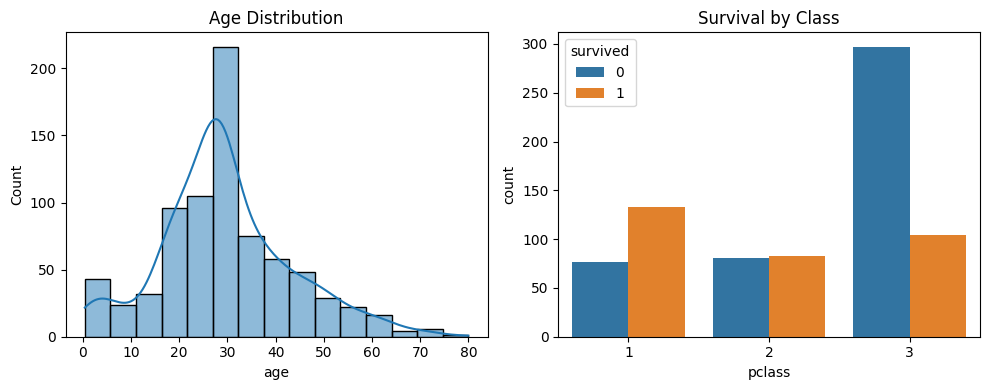

In [ ]:
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
sns.histplot(df_clean['age'], bins=15, kde=True)
plt.title('Age Distribution')

plt.subplot(1, 2, 2)
sns.countplot(data=df_clean, x='pclass', hue='survived')
plt.title('Survival by Class')
plt.tight_layout()
plt.show()

### Step 4b: Additional Visualizations
This step adds more exploration of survival rates based on gender and fare.

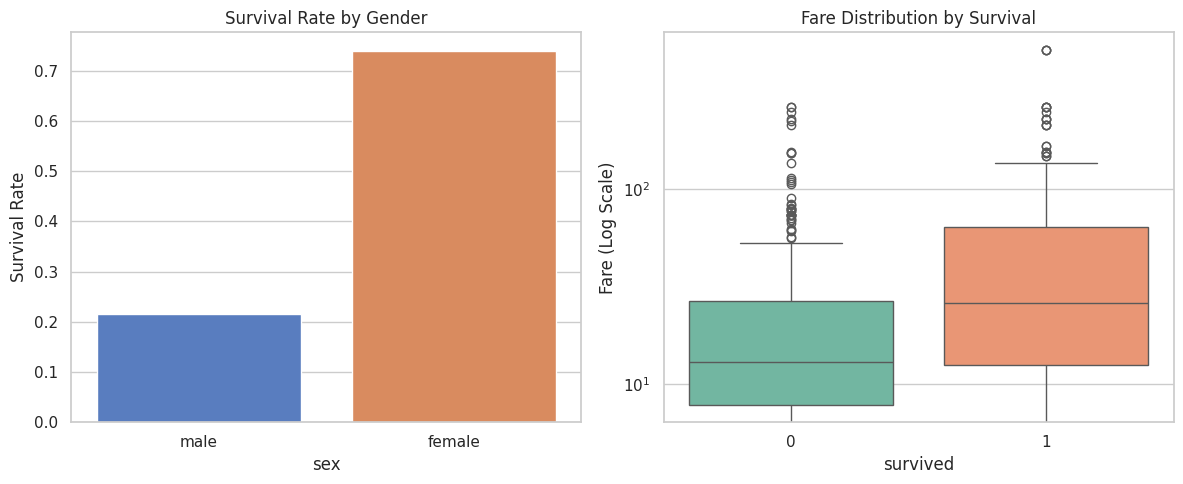

In [6]:
plt.figure(figsize=(12, 5))

# Subplot 1: Survival Rate by Gender
plt.subplot(1, 2, 1)
sns.barplot(data=df_clean, x='sex', y='survived', errorbar=None, palette='muted', hue='sex', legend=False)
plt.title('Survival Rate by Gender')
plt.ylabel('Survival Rate')

# Subplot 2: Fare Distribution by Survival Status
plt.subplot(1, 2, 2)
sns.boxplot(data=df_clean, x='survived', y='fare', palette='Set2', hue='survived', legend=False)
plt.title('Fare Distribution by Survival')
plt.yscale('log')
plt.ylabel('Fare (Log Scale)')

plt.tight_layout()
plt.show()

### Step 4c: Correlation Heatmap
This heatmap visualizes the correlation between numerical variables in the cleaned Titanic dataset.

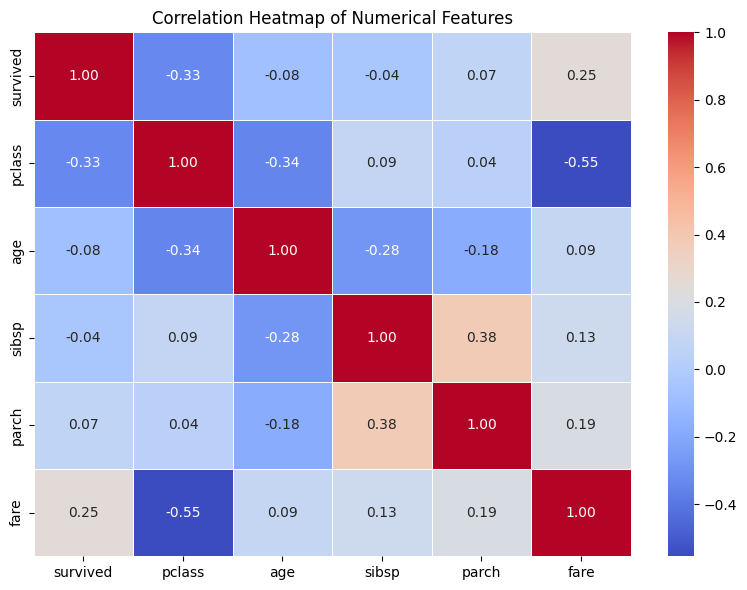

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

# Select only the numerical columns for correlation calculation
numerical_cols = df_clean.select_dtypes(include=['float64', 'int64'])

plt.figure(figsize=(8, 6))
sns.heatmap(numerical_cols.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap of Numerical Features')
plt.tight_layout()
plt.show()

### Step 5: Encode and Scale
This step converts category labels to numbers and scales the numerical values.

In [ ]:
df_encoded = pd.get_dummies(df_clean, columns=['sex', 'embarked'], drop_first=True, dtype=int)
scaler = StandardScaler()
scale_cols = ['age', 'fare', 'sibsp', 'parch']
df_encoded[scale_cols] = scaler.fit_transform(df_encoded[scale_cols])
display(df_encoded.head())

,survived,pclass,age,sibsp,parch,fare,class,who,adult_male,embark_town,alive,alone,sex_male,embarked_Q,embarked_S
0,0,3,-0.551060,0.475876,-0.500754,-0.527515,Third,man,True,Southampton,no,False,1,0,1
1,1,1,0.611945,0.475876,-0.500754,0.695086,First,woman,False,Cherbourg,yes,False,0,0,0
2,1,3,-0.260308,-0.534545,-0.500754,-0.514627,Third,woman,False,Southampton,yes,True,0,0,1
3,1,1,0.393881,0.475876,-0.500754,0.347909,First,woman,False,Southampton,yes,False,0,0,1
4,0,3,0.393881,-0.534545,-0.500754,-0.512240,Third,man,True,Southampton,no,True,1,0,1


### Step 6: Save Cleaned Dataset
This final step saves our prepared dataset to a CSV file.

In [ ]:
df_encoded.to_csv('Titanic_Prepared_Dataset.csv', index=False)
print("Dataset prepared and saved successfully!")

Dataset prepared and saved successfully!
